# Mô hình YOLOv8n nhận diện vật cản cho ứng dụng Vision Assist

**Mục tiêu:** phát hiện các vật thể phía trước (người, ghế, bàn, xe…) trong khung hình camera, chạy **100% trên thiết bị** bằng TensorFlow Lite, để app mô tả cảnh và cảnh báo khi vật lớn chiếm gần hết khung hình.

**Vì sao không huấn luyện lại:**
- YOLOv8n của Ultralytics đã được huấn luyện sẵn trên **COCO 2017** (80 lớp đồ vật thường gặp: người, xe, ghế, bàn, sofa, chậu cây…), phủ phần lớn vật cản trong nhà và trên đường.
- Thời gian dự án ngắn, nhóm không có bộ dữ liệu vật cản tự gán nhãn đủ lớn; dùng mô hình sẵn có giúp tập trung vào phần tích hợp trên điện thoại (tiền xử lý camera, giải mã, cảnh báo).
- Bản **n (nano)** nhỏ nhất họ YOLOv8, phù hợp chạy thời gian thực trên điện thoại.

**Giới hạn cần nói rõ:** COCO **không có** lớp cửa, cầu thang, ổ gà, cột điện… nên app không nhận ra các vật này. App chỉ mang tính hỗ trợ, người dùng vẫn phải dùng gậy dò đường.

**Quy trình trong notebook:**
1. Kiểm tra môi trường
2. Cấu hình đường dẫn (giống app)
3. Khảo sát mô hình: số tham số, 80 lớp, nhóm lớp app dùng
4. Khảo sát ảnh minh họa COCO128
5. Chạy thử dự đoán, so sánh với nhãn gốc
6. Chạy `val` trên COCO128 (chỉ minh họa quy trình, **không** phải đánh giá thật)
7. Xuất ONNX 640 và kiểm chứng ONNX khớp PyTorch, dùng **đúng tiền xử lý của app**
8. Kiểm chứng file `assets/models/obstacle_yolov8n.tflite` app đang dùng
9. Tổng kết: đã kiểm chứng gì, còn gì chưa

In [1]:
# @title Bước 1: Kiểm tra môi trường
import sys, os, platform, json, shutil, subprocess, tempfile, time
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch
import ultralytics
from ultralytics import YOLO

print('=' * 60)
print(f'- Python:       {sys.version.split()[0]} ({platform.system()})')
print(f'- PyTorch:      {torch.__version__}')
print(f'- Ultralytics:  {ultralytics.__version__}')
print(f'- CUDA:         {torch.cuda.is_available()}')
try:
    import onnxruntime as ort
    print(f'- onnxruntime:  {ort.__version__}')
except ImportError:
    ort = None
    print('- onnxruntime:  (chua cai) -> buoc 7 se bo qua phan kiem chung ONNX')
print('=' * 60)

- Python:       3.11.9 (Windows)
- PyTorch:      2.5.1+cu121
- Ultralytics:  8.4.200
- CUDA:         True
- onnxruntime:  1.31.1


## Bước 2: Cấu hình đường dẫn và tham số (khớp với app)

In [2]:
# @title Bang cau hinh
def find_ml_root() -> Path:
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if cand.name == 'ml_training':
            return cand
        if (cand / 'ml_training').is_dir():
            return cand / 'ml_training'
    return p

ML_ROOT     = find_ml_root()
PROJECT     = ML_ROOT.parent
WEIGHTS     = ML_ROOT / 'notebooks' / 'yolov8n.pt'            # trong so huan luyen san (COCO)
COCO128     = ML_ROOT / 'data' / 'obstacle_coco128'           # anh minh hoa (tap con COCO train2017)
APP_TFLITE  = PROJECT / 'assets' / 'models' / 'obstacle_yolov8n.tflite'   # file app dang dung (CHI DOC)
APP_LABELS  = PROJECT / 'assets' / 'models' / 'coco_labels.txt'
OUTPUT_DIR  = ML_ROOT / 'outputs' / 'obstacle_yolov8n'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Tham so giong lib/features/obstacle/data/obstacle_detector.dart
IMG_SIZE    = 640     # app dung input 640x640
CONF        = 0.4     # scoreThreshold
IOU         = 0.5     # iouThreshold
PAD_VALUE   = 114     # letterbox dem mau xam nhu Ultralytics

for name, p in [('WEIGHTS', WEIGHTS), ('COCO128', COCO128), ('APP_TFLITE', APP_TFLITE), ('APP_LABELS', APP_LABELS)]:
    print(f'{name:11s} {"OK " if p.exists() else "THIEU"}  {p}')

if not WEIGHTS.exists():
    # Ultralytics tu tai yolov8n.pt neu chua co
    WEIGHTS = Path('yolov8n.pt')

WEIGHTS     OK   C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\notebooks\yolov8n.pt
COCO128     OK   C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\data\obstacle_coco128
APP_TFLITE  OK   C:\Personal_data\CDCNTT\Project\vision_assist\assets\models\obstacle_yolov8n.tflite
APP_LABELS  OK   C:\Personal_data\CDCNTT\Project\vision_assist\assets\models\coco_labels.txt


## Bước 3: Khảo sát mô hình

App chỉ đọc lên những lớp có ích cho người khiếm thị khi đi lại. Lớp hiếm (dễ nhận nhầm, vd. quạt trần bị đọc thành "airplane") cần độ tin cậy cao hơn — chi tiết trong `lib/features/obstacle/domain/obstacle_classes.dart`.

In [3]:
model = YOLO(str(WEIGHTS))
names = model.names                      # {0: 'person', 1: 'bicycle', ...}
n_params = sum(p.numel() for p in model.model.parameters())
print(f'So lop: {len(names)} | So tham so: {n_params/1e6:.2f} trieu')

# Thu tu ten lop cua model phai khop file nhan app dung (app tra chi so -> ten theo file nay)
app_labels = [l.strip() for l in APP_LABELS.read_text(encoding='utf-8').splitlines() if l.strip()]
model_labels = [names[i] for i in range(len(names))]
print('Thu tu nhan khop voi assets/models/coco_labels.txt:', app_labels == model_labels)

OBSTACLE_GROUPS = {
    'Nguoi / dong vat': ['person', 'dog', 'cat'],
    'Phuong tien':      ['bicycle', 'car', 'motorcycle', 'bus', 'truck'],
    'Do noi that':      ['chair', 'couch', 'bed', 'dining table', 'bench', 'potted plant', 'tv', 'refrigerator'],
    'Ngoai duong':      ['fire hydrant', 'stop sign', 'parking meter', 'traffic light'],
}
for g, cls in OBSTACLE_GROUPS.items():
    print(f'- {g:17s}: {", ".join(cls)}')

So lop: 80 | So tham so: 3.16 trieu
Thu tu nhan khop voi assets/models/coco_labels.txt: True
- Nguoi / dong vat : person, dog, cat
- Phuong tien      : bicycle, car, motorcycle, bus, truck
- Do noi that      : chair, couch, bed, dining table, bench, potted plant, tv, refrigerator
- Ngoai duong      : fire hydrant, stop sign, parking meter, traffic light


## Bước 4: Khảo sát ảnh minh họa COCO128

So anh: 128 | so file nhan: 128


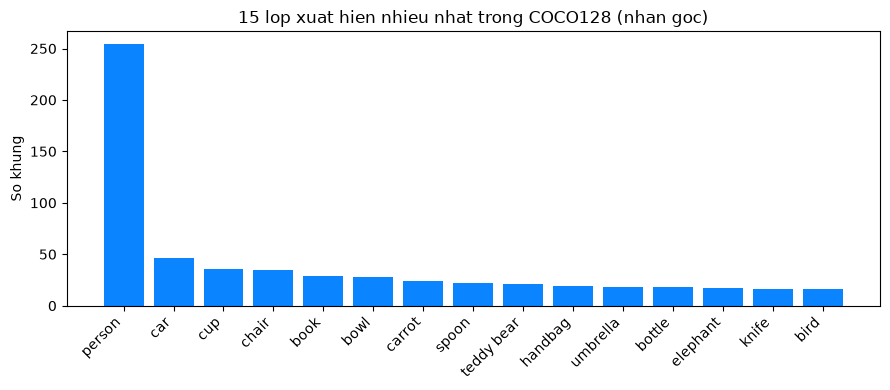

In [4]:
img_dir = COCO128 / 'images' / 'train2017'
lbl_dir = COCO128 / 'labels' / 'train2017'
images = sorted(img_dir.glob('*.jpg'))
print(f'So anh: {len(images)} | so file nhan: {len(list(lbl_dir.glob("*.txt")))}')

def read_labels(img_path: Path):
    f = lbl_dir / (img_path.stem + '.txt')
    if not f.exists():
        return []
    rows = []
    for line in f.read_text().splitlines():
        if line.strip():
            c, x, y, w, h = line.split()[:5]
            rows.append((int(c), float(x), float(y), float(w), float(h)))
    return rows

cnt = Counter(names[c] for p in images for c, *_ in read_labels(p))
top = cnt.most_common(15)
plt.figure(figsize=(9, 4))
plt.bar([t[0] for t in top], [t[1] for t in top], color='#0A84FF')
plt.xticks(rotation=45, ha='right'); plt.ylabel('So khung')
plt.title('15 lop xuat hien nhieu nhat trong COCO128 (nhan goc)')
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'coco128_class_counts.png', dpi=120); plt.show()

## Bước 5: Chạy thử dự đoán và so sánh với nhãn gốc

Trái: **nhãn gốc** do con người gán (COCO). Phải: **dự đoán của YOLOv8n** với ngưỡng giống app (`conf=0.4`, `iou=0.5`).

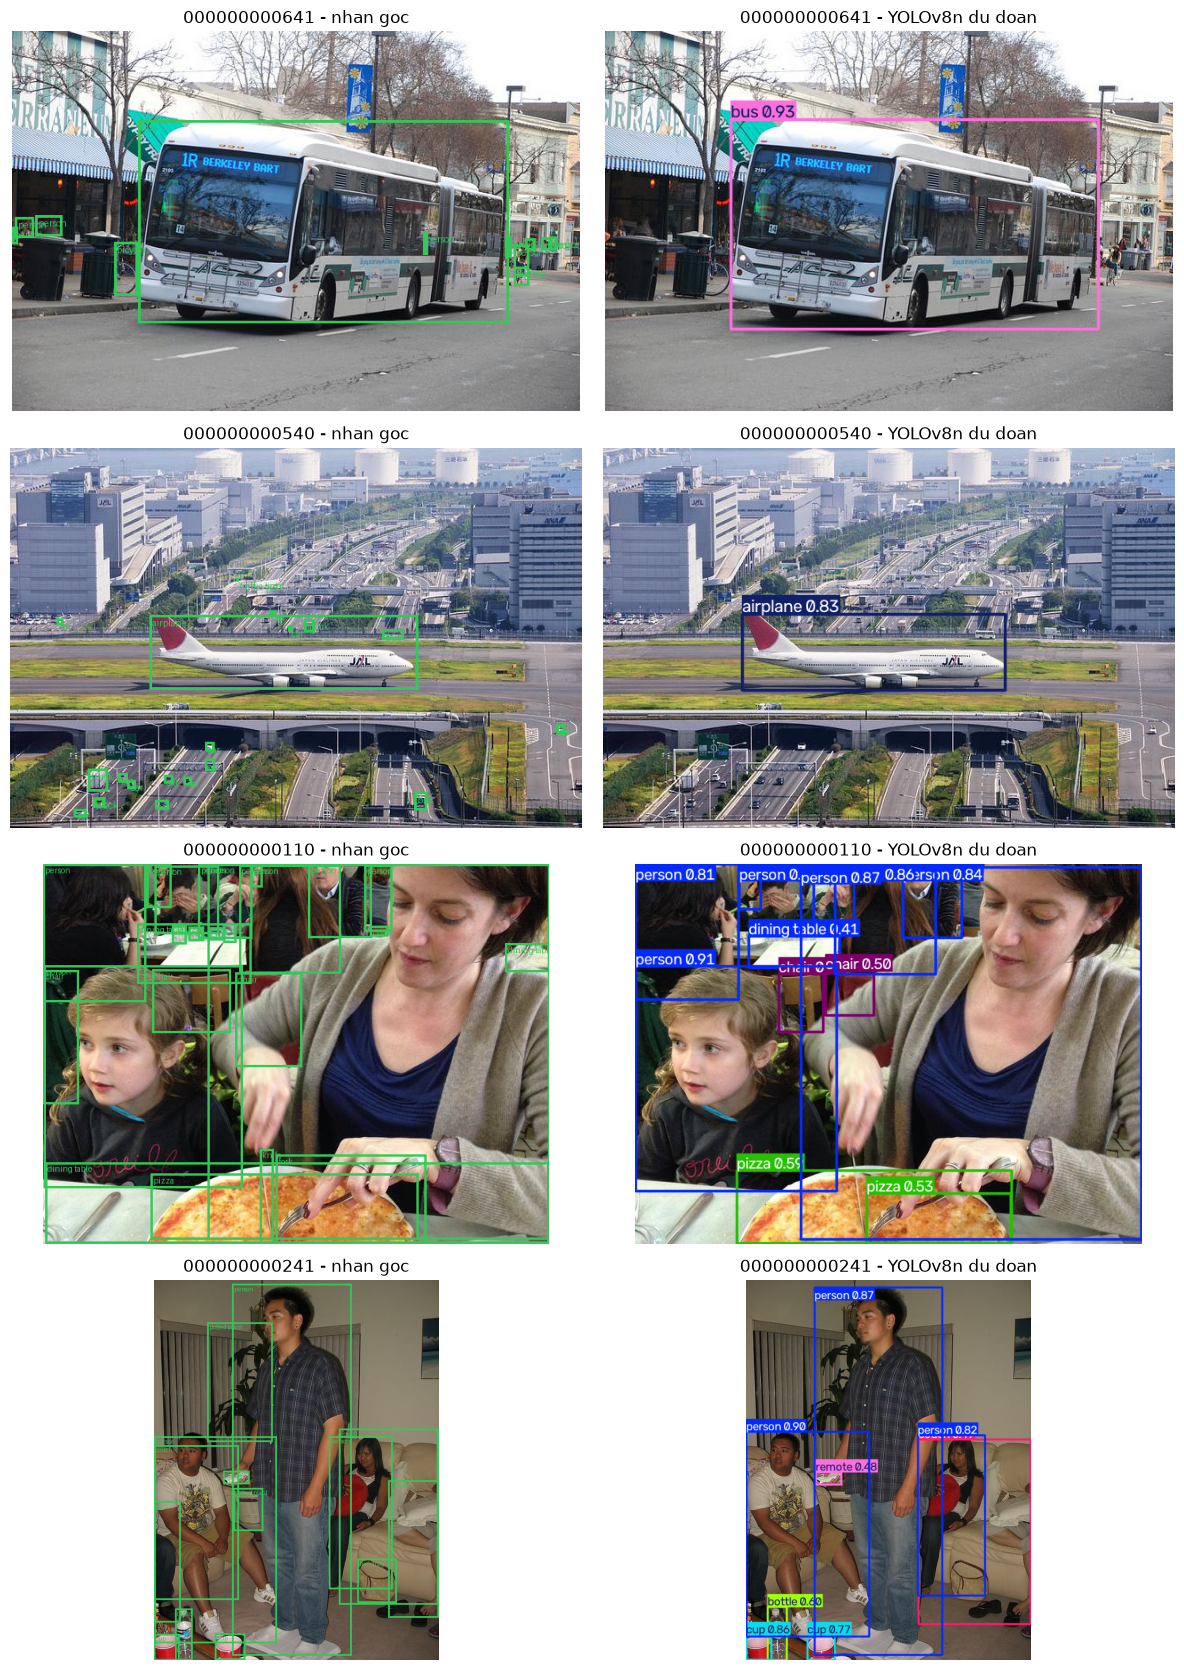

In [5]:
SAMPLES = ['000000000641', '000000000540', '000000000110', '000000000241']
SAMPLES = [s for s in SAMPLES if (img_dir / f'{s}.jpg').exists()] or [p.stem for p in images[:4]]

def draw_gt(img_path):
    im = Image.open(img_path).convert('RGB'); W, H = im.size; d = ImageDraw.Draw(im)
    for c, x, y, w, h in read_labels(img_path):
        x0, y0, x1, y1 = (x-w/2)*W, (y-h/2)*H, (x+w/2)*W, (y+h/2)*H
        d.rectangle([x0, y0, x1, y1], outline='#34C759', width=3)
        d.text((x0+3, y0+2), names[c], fill='#34C759')
    return im

fig, axes = plt.subplots(len(SAMPLES), 2, figsize=(12, 4.2*len(SAMPLES)))
for row, s in zip(np.atleast_2d(axes), SAMPLES):
    p = img_dir / f'{s}.jpg'
    res = model.predict(str(p), imgsz=IMG_SIZE, conf=CONF, iou=IOU, verbose=False)[0]
    row[0].imshow(draw_gt(p)); row[0].set_title(f'{s} - nhan goc'); row[0].axis('off')
    row[1].imshow(res.plot()[..., ::-1]); row[1].set_title(f'{s} - YOLOv8n du doan'); row[1].axis('off')
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'gt_vs_pred.png', dpi=110); plt.show()

## Bước 6: Chạy `val` trên COCO128 — chỉ để minh họa quy trình

> **Cảnh báo:** COCO128 là 128 ảnh **thuộc tập huấn luyện** `train2017` mà YOLOv8n đã học, nên mAP ở đây **cao hơn thực tế** và **không** phải đánh giá khả năng tổng quát. Không dùng con số này làm độ chính xác của app. Đánh giá thật cần ảnh chưa từng thấy (vd. COCO `val2017`) và quan trọng hơn là **ảnh chụp từ camera điện thoại trong môi trường người dùng**.

In [6]:
names_yaml = '\n'.join(f'  {i}: {names[i]}' for i in range(len(names)))
data_yaml = OUTPUT_DIR / 'coco128_obstacle.yaml'
data_yaml.write_text(
    f'path: {COCO128.as_posix()}\ntrain: images/train2017\nval: images/train2017\nnames:\n{names_yaml}\n',
    encoding='utf-8')

metrics = model.val(data=str(data_yaml), imgsz=IMG_SIZE, batch=8, conf=0.001, iou=0.6,
                    plots=False, verbose=False, project=str(OUTPUT_DIR), name='val_coco128', exist_ok=True)
summary = {
    'dataset': 'COCO128 (tap con COCO train2017, DA DUOC HOC) - chi minh hoa, khong phai danh gia',
    'imgsz': IMG_SIZE,
    'mAP50': round(float(metrics.box.map50), 4),
    'mAP50_95': round(float(metrics.box.map), 4),
}
(OUTPUT_DIR / 'val_coco128_illustrative.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(summary, ensure_ascii=False, indent=2))

Ultralytics 8.4.200  Python-3.11.9 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)


YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 464.7±109.5 MB/s, size: 50.6 KB)


val: Scanning C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\data\obstacle_coco128\labels\train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 6% ╸─────────── 1/16 43.1s/it 12.9s<10:47

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 18% ━━────────── 3/16 5.7it/s 13.0s<2.3s

... (6 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 1.2it/s 13.9s

                   all        128        929      0.638      0.538      0.608      0.444


Speed: 1.0ms preprocess, 7.3ms inference, 0.0ms loss, 0.9ms postprocess per image


{
  "dataset": "COCO128 (tap con COCO train2017, DA DUOC HOC) - chi minh hoa, khong phai danh gia",
  "imgsz": 640,
  "mAP50": 0.6079,
  "mAP50_95": 0.4437
}


## Bước 7: Xuất ONNX và kiểm chứng ONNX khớp PyTorch (tiền xử lý giống app)

Đường xuất model của app: `yolov8n.pt → ONNX (imgsz 640) → onnx2tf → TFLite FP16`.

Hàm `letterbox_like_app` làm **giống hệt** `yuvToLetterboxedRgbFloat` trong `lib/core/camera/frame_converter.dart`: giữ tỉ lệ, đặt ảnh giữa, đệm xám 114, lấy mẫu điểm gần nhất, RGB chia 255.
Hàm `decode_like_app` giống `lib/features/obstacle/domain/yolo_decoder.dart`: đầu ra `[1, 84, 8400]` (4 tọa độ cx, cy, w, h theo **pixel không gian model** + 80 điểm lớp), lọc ngưỡng, NMS theo lớp.

In [7]:
def letterbox_like_app(img: Image.Image, size: int = IMG_SIZE):
    # Tra ve (input NHWC float32 [1,S,S,3], scale, padX, padY) giong app.
    src = np.asarray(img.convert('RGB'), dtype=np.float32) / 255.0
    H, W = src.shape[:2]
    scale = min(size / W, size / H)
    new_w, new_h = round(W * scale), round(H * scale)
    pad_x, pad_y = (size - new_w) / 2, (size - new_h) / 2
    out = np.full((size, size, 3), PAD_VALUE / 255.0, dtype=np.float32)
    oy, ox = np.mgrid[0:size, 0:size]
    rx = np.floor((ox + 0.5 - pad_x) / scale).astype(int)
    ry = np.floor((oy + 0.5 - pad_y) / scale).astype(int)
    inside = (rx >= 0) & (rx < W) & (ry >= 0) & (ry < H)
    out[inside] = src[ry[inside], rx[inside]]
    return out[None], scale, pad_x, pad_y

def nms(boxes, scores, iou_thr):
    order = scores.argsort()[::-1]; keep = []
    while order.size:
        i = order[0]; keep.append(i)
        xx1 = np.maximum(boxes[i, 0], boxes[order[1:], 0]); yy1 = np.maximum(boxes[i, 1], boxes[order[1:], 1])
        xx2 = np.minimum(boxes[i, 2], boxes[order[1:], 2]); yy2 = np.minimum(boxes[i, 3], boxes[order[1:], 3])
        inter = np.clip(xx2 - xx1, 0, None) * np.clip(yy2 - yy1, 0, None)
        area = lambda b: (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
        iou = inter / (area(boxes[[i]]) + area(boxes[order[1:]]) - inter + 1e-9)
        order = order[1:][iou <= iou_thr]
    return keep

def decode_like_app(out, scale, pad_x, pad_y, W, H, conf=CONF, iou=IOU):
    # out: [1, 84, N] -> list (ten_lop, diem, x0, y0, x1, y1) theo pixel anh goc
    p = out[0]
    cls_scores = p[4:]
    cls = cls_scores.argmax(0); score = cls_scores.max(0)
    m = score >= conf
    cx, cy, w, h = p[0, m], p[1, m], p[2, m], p[3, m]
    boxes = np.stack([cx - w/2, cy - h/2, cx + w/2, cy + h/2], 1)
    boxes[:, [0, 2]] = ((boxes[:, [0, 2]] - pad_x) / scale).clip(0, W)
    boxes[:, [1, 3]] = ((boxes[:, [1, 3]] - pad_y) / scale).clip(0, H)
    score, cls = score[m], cls[m]
    dets = []
    for c in np.unique(cls):
        idx = np.where(cls == c)[0]
        for k in nms(boxes[idx], score[idx], iou):
            j = idx[k]; dets.append((names[int(c)], float(score[j]), *boxes[j].tolist()))
    return sorted(dets, key=lambda d: -d[1])

def run_torch_raw(x_nhwc):
    # Chay mo hinh PyTorch tren dung tensor da letterbox (khong de Ultralytics tu tien xu ly).
    net = model.model.float().eval()
    with torch.no_grad():
        y = net(torch.from_numpy(x_nhwc.transpose(0, 3, 1, 2).copy()))
    y = y[0] if isinstance(y, (list, tuple)) else y
    return y.cpu().numpy()

def print_dets(title, dets, k=6):
    print(title)
    for n, s, *b in dets[:k]:
        print(f'   {n:14s} {s:.2f}  [{b[0]:.0f}, {b[1]:.0f}, {b[2]:.0f}, {b[3]:.0f}]')

In [8]:
# Xuat ONNX vao OUTPUT_DIR (KHONG dong vao file trong assets/)
onnx_tmp = model.export(format='onnx', imgsz=IMG_SIZE, simplify=True, verbose=False)
ONNX_PATH = OUTPUT_DIR / f'yolov8n_{IMG_SIZE}.onnx'
shutil.move(str(onnx_tmp), ONNX_PATH)
print('Da xuat:', ONNX_PATH, f'({ONNX_PATH.stat().st_size/1e6:.1f} MB)')

VERIFY_IMG = Path(ultralytics.__file__).parent / 'assets' / 'bus.jpg'
if not VERIFY_IMG.exists():
    VERIFY_IMG = img_dir / f'{SAMPLES[0]}.jpg'
img = Image.open(VERIFY_IMG); W, H = img.size
x, scale, pad_x, pad_y = letterbox_like_app(img)

torch_out = run_torch_raw(x)
print('Shape dau ra PyTorch:', torch_out.shape)
dets_torch = decode_like_app(torch_out, scale, pad_x, pad_y, W, H)
print_dets(f'PyTorch tren {VERIFY_IMG.name}:', dets_torch)

if ort is not None:
    sess = ort.InferenceSession(str(ONNX_PATH), providers=['CPUExecutionProvider'])
    onnx_out = sess.run(None, {sess.get_inputs()[0].name: x.transpose(0, 3, 1, 2).copy()})[0]
    dets_onnx = decode_like_app(onnx_out, scale, pad_x, pad_y, W, H)
    print_dets('ONNX:', dets_onnx)
    print(f'Sai so tuyet doi lon nhat ONNX vs PyTorch (dau ra tho): {np.abs(onnx_out - torch_out).max():.5f}')

Ultralytics 8.4.200  Python-3.11.9 torch-2.5.1+cu121 CPU (AMD Ryzen 7 7435HS)


YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs



PyTorch: starting from 'C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\notebooks\yolov8n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (6.2 MB)



ONNX: starting export with onnx 1.23.2 opset 18...


ONNX: slimming with onnxslim 0.1.98...


ONNX: export success  0.9s, saved as 'C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\notebooks\yolov8n.onnx' (12.3 MB)



Export complete (1.1s)
Results saved to C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\notebooks\yolov8n.onnx
Predict:         yolo predict task=detect model=C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\notebooks\yolov8n.onnx imgsz=640 
Validate:        yolo val task=detect model=C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\notebooks\yolov8n.onnx imgsz=640 data=coco.yaml 
Visualize:       https://netron.app


Da xuat: C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\outputs\obstacle_yolov8n\yolov8n_640.onnx (12.9 MB)
Shape dau ra PyTorch: (1, 84, 8400)
PyTorch tren bus.jpg:
   person         0.88  [670, 374, 810, 878]
   person         0.88  [222, 408, 343, 857]
   person         0.86  [51, 397, 244, 905]
   bus            0.83  [32, 229, 805, 768]
ONNX:
   person         0.88  [670, 374, 810, 878]
   person         0.88  [222, 408, 343, 857]
   person         0.86  [51, 397, 244, 905]
   bus            0.83  [32, 229, 805, 768]
Sai so tuyet doi lon nhat ONNX vs PyTorch (dau ra tho): 0.00357


## Bước 8: Kiểm chứng file TFLite app đang dùng

File `assets/models/obstacle_yolov8n.tflite` được tạo bằng **onnx2tf** (FP16) từ file ONNX ở bước 7:

```bash
onnx2tf -i yolov8n_640.onnx -o saved_model   # sinh *_float16.tflite
```

Trên Windows, export TFLite trực tiếp của Ultralytics không chạy được; nhóm dùng một môi trường Python riêng có `onnx2tf`, `tensorflow`, `ai-edge-litert`. Ô dưới đây:
- nếu môi trường hiện tại có TFLite interpreter thì chạy trực tiếp;
- nếu không, thử gọi Python của môi trường riêng (biến môi trường `TFLITE_PYTHON`, mặc định `%TEMP%\y2`);
- không có cả hai thì bỏ qua và báo rõ.

Mục tiêu: xác nhận **shape vào/ra** đúng như code app giả định và **kết quả khớp PyTorch** trên cùng ảnh, cùng tiền xử lý.

Moi truong TFLite: C:\Users\admin\AppData\Local\Temp\y2\Scripts\python.exe
Shape vao/ra cua file app: {'input': [1, 640, 640, 3], 'input_dtype': 'float32', 'output': [1, 84, 8400]}
TFLite (file cua app):
   person         0.88  [670, 374, 810, 878]
   person         0.88  [222, 408, 343, 857]
   person         0.86  [51, 397, 244, 905]
   bus            0.83  [32, 229, 805, 768]
Sai so tuyet doi lon nhat TFLite vs PyTorch (dau ra tho): 2.9443
Danh sach lop phat hien giong PyTorch: True


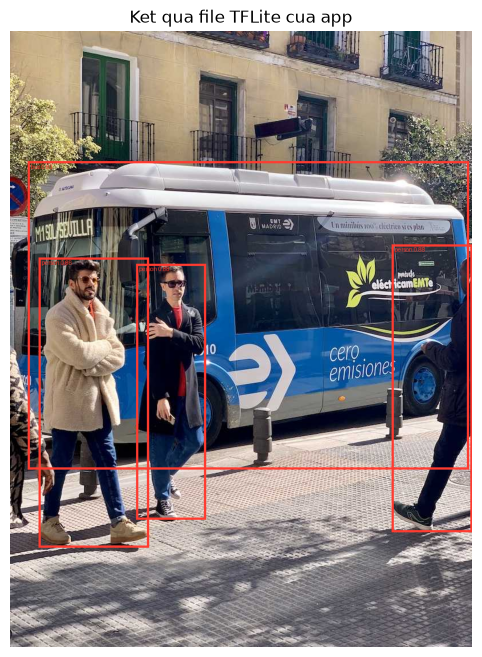

In [9]:
TFLITE_RUNNER = r'''
import sys, json, numpy as np
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    from tensorflow.lite import Interpreter
model_path, in_npy, out_npy = sys.argv[1:4]
it = Interpreter(model_path=model_path); it.allocate_tensors()
inp, out = it.get_input_details()[0], it.get_output_details()[0]
it.set_tensor(inp['index'], np.load(in_npy).astype(inp['dtype']))
it.invoke()
np.save(out_npy, it.get_tensor(out['index']))
print(json.dumps({'input': [int(v) for v in inp['shape']], 'input_dtype': str(np.dtype(inp['dtype'])),
                  'output': [int(v) for v in out['shape']]}))
'''

def run_app_tflite(x_nhwc):
    work = Path(tempfile.mkdtemp())
    (work / 'runner.py').write_text(TFLITE_RUNNER, encoding='utf-8')
    np.save(work / 'in.npy', x_nhwc)
    candidates = [sys.executable, os.environ.get('TFLITE_PYTHON', ''),
                  str(Path(os.environ.get('TEMP', '/tmp')) / 'y2' / 'Scripts' / 'python.exe')]
    for py in [c for c in candidates if c and Path(c).exists()]:
        r = subprocess.run([py, '-I', str(work / 'runner.py'), str(APP_TFLITE), str(work / 'in.npy'), str(work / 'out.npy')],
                           capture_output=True, text=True)
        if r.returncode == 0:
            info = json.loads(r.stdout.strip().splitlines()[-1])
            return np.load(work / 'out.npy'), info, py
    return None, None, None

if not APP_TFLITE.exists():
    print('Khong tim thay', APP_TFLITE)
else:
    tfl_out, info, used = run_app_tflite(x)
    if tfl_out is None:
        print('Khong co moi truong TFLite (ai-edge-litert/tensorflow) -> bo qua kiem chung TFLite.')
    else:
        print('Moi truong TFLite:', used)
        print('Shape vao/ra cua file app:', info)
        assert info['input'] == [1, IMG_SIZE, IMG_SIZE, 3], 'Input khac gia dinh cua app'
        assert info['output'] == [1, 84, (IMG_SIZE // 8) ** 2 + (IMG_SIZE // 16) ** 2 + (IMG_SIZE // 32) ** 2], 'Output khac gia dinh'
        dets_tfl = decode_like_app(tfl_out, scale, pad_x, pad_y, W, H)
        print_dets('TFLite (file cua app):', dets_tfl)
        print(f'Sai so tuyet doi lon nhat TFLite vs PyTorch (dau ra tho): {np.abs(tfl_out - torch_out).max():.4f}')
        same = [d[0] for d in dets_tfl] == [d[0] for d in dets_torch]
        print('Danh sach lop phat hien giong PyTorch:', same)

        # Ve ket qua TFLite len anh de minh hoa
        im = img.convert('RGB').copy(); dr = ImageDraw.Draw(im)
        for n, s, x0, y0, x1, y1 in dets_tfl:
            dr.rectangle([x0, y0, x1, y1], outline='#FF3B30', width=4)
            dr.text((x0 + 4, y0 + 3), f'{n} {s:.2f}', fill='#FF3B30')
        im.save(OUTPUT_DIR / 'app_tflite_result.jpg')
        plt.figure(figsize=(7, 8)); plt.imshow(im); plt.axis('off'); plt.title('Ket qua file TFLite cua app'); plt.show()

## Bước 9: Tổng kết

**Đã kiểm chứng trong notebook (trên máy tính):**
- Thứ tự 80 lớp của mô hình khớp `assets/models/coco_labels.txt` mà app dùng.
- File ONNX xuất ra cho kết quả khớp PyTorch với **tiền xử lý giống hệt app**.
- File `obstacle_yolov8n.tflite` của app có shape vào `[1, 640, 640, 3]`, ra `[1, 84, 8400]`, tọa độ theo pixel không gian model — đúng giả định trong `obstacle_detector.dart` — và cho cùng các lớp với PyTorch (nếu bước 8 chạy được).

**Chưa kiểm chứng / không được suy ra từ notebook này:**
- **Độ chính xác thực tế** trên camera điện thoại: mAP ở bước 6 tính trên ảnh mô hình đã học nên không có giá trị đánh giá.
- **Tốc độ trên điện thoại**: phải đo trên thiết bị thật (app ghi thời gian xử lý mỗi khung hình vào log).
- Khoảng cách tới vật: app **không** đọc số mét vì ước lượng từ khung bao không đáng tin; chỉ cảnh báo khi vật lớn chiếm gần hết khung hình.
- Các vật không có trong COCO (cửa, cầu thang, ổ gà…) app không nhận ra.